# Prince Rupert's cube

Can a cube pass through a hole in a cube of the same size? Prince Rupert of the Rhine bet that it can, and won.
John Wallis showed in 1693 that a tunnel along the cube's space diagonal fits a cube about 1.035 times as large, and
Pieter Nieuwland found the largest such cube, 3√2/4 or about 1.0607 times as large, published in 1816.

A cube passes through a straight tunnel in another cube when its square face fits into the other cube's shadow
along the tunnel. Here, the shadow is built from the cube's faces projected onto a plane, the largest square inside
it is found by a search over the direction, and the tunnel is cut into the cube in 3D.

![A unit cube with a tunnel along (2, 1, 2) for a cube of side 1.04](../_static/gallery/prince-ruperts-cube.png){.result}

In [1]:
import math

import matplotlib.pyplot as plt
import netgen.occ as occ
import numpy as np
from scipy.optimize import minimize
import planex as px

## The shadow of a cube

The example is a unit cube. Its shadow along a direction d is its projection onto a plane perpendicular to d, and it
is the union of the projections of its six faces. `px.Project` projects each face onto a plane through the cube's
center, so the shadow is centered on the plane's origin, and `px.Unify` merges them. The area of the shadow is
|dx| + |dy| + |dz|, the sum of what the three faces that face d contribute.

In [2]:
cube = occ.Box(occ.Pnt(0, 0, 0), occ.Pnt(1, 1, 1))


def direction(theta, phi):
    return (math.sin(theta) * math.cos(phi), math.sin(theta) * math.sin(phi), math.cos(theta))


def shadow(d):
    plane = px.Plane(origin=(0.5, 0.5, 0.5), normal=d)
    return px.Unify([px.Face(px.Project(face, plane)) for face in cube.faces])


d = direction(0.9, 0.7)
print("area", shadow(d).mass, "exact", abs(d[0]) + abs(d[1]) + abs(d[2]))

area 1.7253644852602126 exact 1.7253644852602128


## The largest square in a shadow

The shadow is convex, so a square fits when its four corners lie in the shadow. The shadow is also symmetric about
its center, so the largest square can be centered there, and only its size and its angle are left. `largest` finds
the largest side for an angle by bisection, with `Contains` testing the corners.

In [3]:
def largest(outline, angle):
    turn = np.array([[math.cos(angle), -math.sin(angle)], [math.sin(angle), math.cos(angle)]])
    corners = np.array([(1, 1), (-1, 1), (-1, -1), (1, -1)]) @ turn.T / 2
    low, high = 0.0, 2.0
    for _ in range(40):
        side = (low + high) / 2
        if outline.Contains(side * corners).all():
            low = side
        else:
            high = side
    return low


def square(outline, side, angle):
    return px.QuickSketch(outline).RectangleC(side, side).Face().Rotated((0, 0), math.degrees(angle))

Along the space diagonal, the shadow is a regular hexagon of side √(2/3). The largest square in a regular hexagon of
side a is (3 − √3) a, which is Wallis's 1.035:

In [4]:
hexagon = shadow((1 / math.sqrt(3), 1 / math.sqrt(3), 1 / math.sqrt(3)))
angles = np.linspace(0, math.pi / 2, 181)
sides = [largest(hexagon, angle) for angle in angles]
wallis = max(sides)
wallis_angle = angles[int(np.argmax(sides))]
print("diagonal", wallis, "exact", (3 - math.sqrt(3)) * math.sqrt(2 / 3))

diagonal 1.03527618040971 exact 1.0352761804100832


## The largest cube

The search lets SciPy's Nelder–Mead method turn the direction, given by two angles, and the square's angle. Started
again from its own result, it settles after a few rounds. The best direction is (2, 1, 2)/3, and the square's side
agrees with Nieuwland's 3√2/4 to about twelve digits.

In [5]:
def side(x):
    return largest(shadow(direction(x[0], x[1])), x[2])


x = [0.8, 0.6, 0.3]
for _ in range(3):
    x = minimize(lambda x: -side(x), x, method="Nelder-Mead", options=dict(xatol=1e-10, fatol=1e-12)).x
best = direction(x[0], x[1])
nieuwland = side(x)
print("largest cube", nieuwland, "exact", 3 * math.sqrt(2) / 4, "difference", nieuwland - 3 * math.sqrt(2) / 4)
print("direction", np.round(best, 6))

largest cube 1.0606601717790909 exact 1.0606601717798214 difference -7.30526750203353e-13
direction [0.666666 0.333333 0.666667]


The two shadows with their squares: on the diagonal, the square touches the hexagon with its four corners on four
sides (a). Along (2, 1, 2), the shadow is a less regular hexagon, and the larger square still fits (b). Subtracting
the shadow from the square leaves nothing:

(a) Along the diagonal square outside the shadow: 0.0
(b) Along (2, 1, 2) square outside the shadow: 0.0


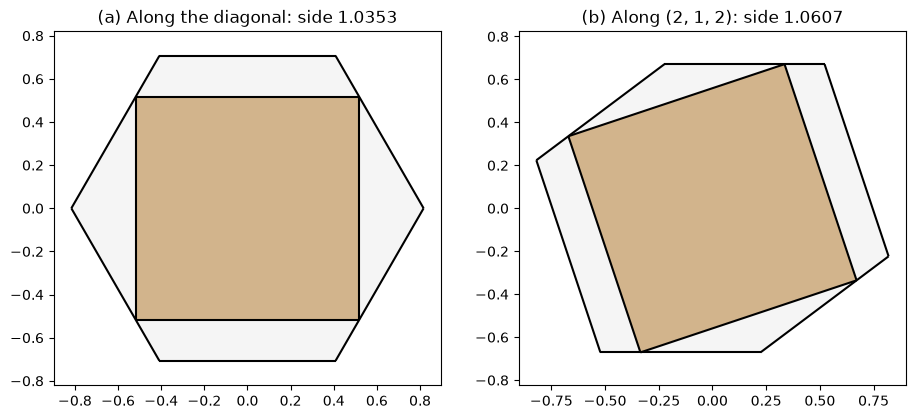

In [6]:
tilted = shadow(best)
fits = {"(a) Along the diagonal": (hexagon, square(hexagon, wallis, wallis_angle)),
        "(b) Along (2, 1, 2)": (tilted, square(tilted, nieuwland, x[2]))}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, (title, (outline, sq)) in zip(axes, fits.items()):
    print(title, "square outside the shadow:", (sq - outline).mass)
    outline.Plot(ax=ax, face_col="whitesmoke", legend=False)
    sq.Plot(ax=ax, face_col="tan", legend=False)
    ax.set_title(f"{title}: side {sq.mass ** 0.5:.4f}")

## The tunnel

A tunnel along (2, 1, 2) slightly larger than a cube of 1.04 leaves a thin ring of the cube around it. `px.Pocket`
cuts the tunnel from a square on the plane through the center, 1.2 to each side. Looking into the tunnel, little of
the cube is left around it:

In [7]:
center = px.Plane(origin=(0.5, 0.5, 0.5), normal=best)
holed = px.Pocket(cube, square(center, 1.05, x[2]), 1.2, 1.2)
holed.faces.col = (0.85, 0.87, 0.9)
print("volume of the ring", holed.mass)
px.Plot3d([holed], euler_angles=[-46, -18, -60])

volume of the ring 0.10475661562370235


`px.Pad` extrudes a cube of side 1.04 from a square on the same plane, partly through the tunnel, here with the
tunnel running to the right:

In [8]:
passing = px.Pad(square(center, 1.04, x[2]), 0.95, 0.09)
passing.faces.col = (0.82, 0.71, 0.55)
print("volume of the cube passing", passing.mass, "exact", 1.04**3)
px.Plot3d([holed, passing], euler_angles=[-25, 19, -30])

volume of the cube passing 1.1248640000000008 exact 1.124864
